In [28]:
import pandas as pd
import numpy as np

from src.preprocess import preprocess
from src.pca_features import aggregate_drills, get_pca_components
from src.plots import create_spider_plot

import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
df = pd.read_csv("data/combine_tracking.csv")
combine_results = pd.read_csv("data/combine_results.csv")

df["time"] = pd.to_datetime(df["time"])

df.head()

,draft_year,event_id,nfl_id,entity_type,time,drill_type,drill_name,attempt,x,y,s,a,dis,dir
0,2025,20250302100900_1740941802777_000,58286,PLAYER,2025-03-02 18:56:38.200,SKILL_DRILLS_OL,OL_PULL_DRILL_FOLD_BLOCK_RIGHT,4,44.785924,28.285528,0.220828,0.682443,0.011085,250.278576
1,2025,20250302100900_1740941802777_000,58286,PLAYER,2025-03-02 18:56:38.300,SKILL_DRILLS_OL,OL_PULL_DRILL_FOLD_BLOCK_RIGHT,4,44.723780,28.297391,0.332931,0.619551,0.003864,257.319206
2,2025,20250302100900_1740941802777_000,58286,PLAYER,2025-03-02 18:56:38.400,SKILL_DRILLS_OL,OL_PULL_DRILL_FOLD_BLOCK_RIGHT,4,44.632680,28.279528,0.481838,0.596455,0.008305,253.176813
3,2025,20250302100900_1740941802777_000,58286,PLAYER,2025-03-02 18:56:38.500,SKILL_DRILLS_OL,OL_PULL_DRILL_FOLD_BLOCK_RIGHT,4,44.544022,28.243767,0.599350,0.664436,0.007964,247.044153
4,2025,20250302100900_1740941802777_000,58286,PLAYER,2025-03-02 18:56:38.600,SKILL_DRILLS_OL,OL_PULL_DRILL_FOLD_BLOCK_RIGHT,4,44.471466,28.210294,0.657540,0.908250,0.005382,240.622668


In [3]:
combine_results.head()

,draft_year,nfl_id,combine_position,combine_height,combine_weight,hand_size,arm_length,wing_span,ten_yd_split,forty,vertical,broad_jump,three_cone,short_shuttle,bench_reps,ngs_athleticism_score,ngs_college_production_score,ngs_final_score
0,2023,56040,TE,77.875,245,10.000,32.250,79.750,1.60,4.84,38.5,125.0,NaN,NaN,NaN,60,NaN,NaN
1,2023,56010,DB,70.625,191,8.750,29.625,72.250,1.58,4.59,33.5,116.0,NaN,NaN,23.0,60,77.0,74.0
2,2023,56085,TE,79.375,255,10.250,34.000,83.125,1.57,4.55,40.0,128.0,6.87,4.12,23.0,97,65.0,79.0
3,2023,56056,WR,72.250,192,9.625,31.875,76.125,1.51,4.33,NaN,NaN,NaN,NaN,NaN,76,68.0,73.0
4,2023,56118,WR,71.625,191,9.500,31.000,75.000,1.52,4.54,38.5,120.0,6.98,4.15,14.0,65,65.0,64.0


In [4]:
df = pd.merge(df, combine_results[["nfl_id", "combine_position"]], how="left", on="nfl_id")
df.head()

,draft_year,event_id,nfl_id,entity_type,time,drill_type,drill_name,attempt,x,y,s,a,dis,dir,combine_position
0,2025,20250302100900_1740941802777_000,58286,PLAYER,2025-03-02 18:56:38.200,SKILL_DRILLS_OL,OL_PULL_DRILL_FOLD_BLOCK_RIGHT,4,44.785924,28.285528,0.220828,0.682443,0.011085,250.278576,OL
1,2025,20250302100900_1740941802777_000,58286,PLAYER,2025-03-02 18:56:38.300,SKILL_DRILLS_OL,OL_PULL_DRILL_FOLD_BLOCK_RIGHT,4,44.723780,28.297391,0.332931,0.619551,0.003864,257.319206,OL
2,2025,20250302100900_1740941802777_000,58286,PLAYER,2025-03-02 18:56:38.400,SKILL_DRILLS_OL,OL_PULL_DRILL_FOLD_BLOCK_RIGHT,4,44.632680,28.279528,0.481838,0.596455,0.008305,253.176813,OL
3,2025,20250302100900_1740941802777_000,58286,PLAYER,2025-03-02 18:56:38.500,SKILL_DRILLS_OL,OL_PULL_DRILL_FOLD_BLOCK_RIGHT,4,44.544022,28.243767,0.599350,0.664436,0.007964,247.044153,OL
4,2025,20250302100900_1740941802777_000,58286,PLAYER,2025-03-02 18:56:38.600,SKILL_DRILLS_OL,OL_PULL_DRILL_FOLD_BLOCK_RIGHT,4,44.471466,28.210294,0.657540,0.908250,0.005382,240.622668,OL


In [5]:
pos_df = {}
for pos in df["combine_position"].unique():
    pos_df[pos] = df[df["combine_position"] == pos].copy()

pos_df.keys()

dict_keys(['OL', 'DL', 'DB', 'TE', 'WR'])

In [6]:
tmp = df[df["entity_type"] == "PLAYER"]

tmp.groupby("event_id")[["nfl_id", "drill_name", "attempt"]].nunique().describe()

,nfl_id,drill_name,attempt
count,6310.0,6310.0,6310.0
mean,1.0,1.0,1.0
std,0.0,0.0,0.0
min,1.0,1.0,1.0
25%,1.0,1.0,1.0
50%,1.0,1.0,1.0
75%,1.0,1.0,1.0
max,1.0,1.0,1.0


In [7]:
tmp.groupby(["nfl_id", "drill_name"])[[ "attempt"]].nunique().describe()

,attempt
count,4986.000000
mean,1.263738
std,0.472766
min,1.000000
25%,1.000000
50%,1.000000
75%,2.000000
max,5.000000


In [8]:
result_pos = {}

for pos in pos_df.keys():
    print(pos)
    result_pos[pos] = preprocess(pos_df[pos])
    print(result_pos[pos].shape, result_pos[pos].columns)


OL


/home/lucabasa/Git/kaggle_competitions/nfl_2026/src/path_features.py:30: RuntimeWarning: invalid value encountered in divide
  kappa = abs(dx * ddy - ddx * dy) / ( dx**2 + dy**2)**(3/2)


(121, 299) Index(['nfl_id', 'FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE_angular_accel_std',
       'OL_PULL_DRILL_DEEP_SHORT_PULL_LEFT_angular_accel_std',
       'OL_PULL_DRILL_FOLD_BLOCK_RIGHT_angular_accel_std',
       'PASS_RUSH_DROP_angular_accel_std', 'SCREEN_DRILL_angular_accel_std',
       'FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE_hard_turn_activity',
       'OL_PULL_DRILL_DEEP_SHORT_PULL_LEFT_hard_turn_activity',
       'OL_PULL_DRILL_FOLD_BLOCK_RIGHT_hard_turn_activity',
       'PASS_RUSH_DROP_hard_turn_activity',
       ...
       'SCREEN_DRILL_movement_efficiency',
       'OL_PULL_DRILL_FOLD_BLOCK_RIGHT_std_curvature',
       'PASS_RUSH_DROP_std_curvature',
       'FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE_total_distance',
       'OL_PULL_DRILL_DEEP_SHORT_PULL_LEFT_total_distance',
       'OL_PULL_DRILL_FOLD_BLOCK_RIGHT_total_distance',
       'PASS_RUSH_DROP_total_distance', 'SCREEN_DRILL_total_distance',
       'OL_PULL_DRILL_FOLD_BLOCK_RIGHT_traj_smoothness',
       'PASS_RUSH_DRO

/home/lucabasa/Git/kaggle_competitions/nfl_2026/src/path_features.py:30: RuntimeWarning: invalid value encountered in divide
  kappa = abs(dx * ddy - ddx * dy) / ( dx**2 + dy**2)**(3/2)


(118, 365) Index(['nfl_id', 'BODY_CONTROL_DRILL_angular_accel_std',
       'FOUR_BAG_AGILITY_DRILL_angular_accel_std',
       'FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION_angular_accel_std',
       'PASS_RUSH_DRILL_angular_accel_std',
       'RUN_AND_CLUB_DRILL_angular_accel_std',
       'RUN_THE_HOOP_DRILL_angular_accel_std',
       'BODY_CONTROL_DRILL_hard_turn_activity',
       'FOUR_BAG_AGILITY_DRILL_hard_turn_activity',
       'FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION_hard_turn_activity',
       ...
       'BODY_CONTROL_DRILL_total_distance',
       'FOUR_BAG_AGILITY_DRILL_total_distance',
       'FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION_total_distance',
       'PASS_RUSH_DRILL_total_distance', 'RUN_AND_CLUB_DRILL_total_distance',
       'RUN_THE_HOOP_DRILL_total_distance',
       'BODY_CONTROL_DRILL_traj_smoothness', 'PASS_RUSH_DRILL_traj_smoothness',
       'RUN_AND_CLUB_DRILL_traj_smoothness',
       'RUN_THE_HOOP_DRILL_traj_smoothness'],
      dtype='object', length=365)

/home/lucabasa/Git/kaggle_competitions/nfl_2026/src/path_features.py:30: RuntimeWarning: invalid value encountered in divide
  kappa = abs(dx * ddy - ddx * dy) / ( dx**2 + dy**2)**(3/2)


(122, 485) Index(['nfl_id', 'BACK_PEDAL_AND_90_DEGREE_BREAK_TO_BALL_angular_accel_std',
       'BACK_PEDAL_AND_TRANSITION_45_DEGREE_REACTION_angular_accel_std',
       'BOX_DRILL_angular_accel_std', 'FORTY_YARD_DASH_angular_accel_std',
       'GAUNTLET_DRILL_angular_accel_std',
       'TERYL_AUSTIN_DRILL_1_angular_accel_std',
       'TERYL_AUSTIN_DRILL_2_angular_accel_std', 'W_DRILL_angular_accel_std',
       'BACK_PEDAL_AND_90_DEGREE_BREAK_TO_BALL_hard_turn_activity',
       ...
       'FORTY_YARD_DASH_total_distance', 'GAUNTLET_DRILL_total_distance',
       'TERYL_AUSTIN_DRILL_1_total_distance',
       'TERYL_AUSTIN_DRILL_2_total_distance', 'W_DRILL_total_distance',
       'BACK_PEDAL_AND_90_DEGREE_BREAK_TO_BALL_traj_smoothness',
       'BACK_PEDAL_AND_TRANSITION_45_DEGREE_REACTION_traj_smoothness',
       'FORTY_YARD_DASH_traj_smoothness',
       'TERYL_AUSTIN_DRILL_1_traj_smoothness', 'W_DRILL_traj_smoothness'],
      dtype='object', length=485)
TE


/home/lucabasa/Git/kaggle_competitions/nfl_2026/src/path_features.py:30: RuntimeWarning: invalid value encountered in divide
  kappa = abs(dx * ddy - ddx * dy) / ( dx**2 + dy**2)**(3/2)


(42, 431) Index(['nfl_id', 'BLOCK_EXPLOSION_angular_accel_std',
       'FLAT_ROUTE_LEFT_angular_accel_std',
       'FORTY_YARD_DASH_angular_accel_std', 'GAUNTLET_DRILL_angular_accel_std',
       'HOOK_ROUTE_RIGHT_angular_accel_std', 'IN_ROUTE_LEFT_angular_accel_std',
       'WHEEL_ROUTE_LEFT_angular_accel_std',
       'BLOCK_EXPLOSION_hard_turn_activity',
       'FLAT_ROUTE_LEFT_hard_turn_activity',
       ...
       'GAUNTLET_DRILL_total_distance', 'HOOK_ROUTE_RIGHT_total_distance',
       'IN_ROUTE_LEFT_total_distance', 'WHEEL_ROUTE_LEFT_total_distance',
       'FLAT_ROUTE_LEFT_traj_smoothness', 'FORTY_YARD_DASH_traj_smoothness',
       'GAUNTLET_DRILL_traj_smoothness', 'HOOK_ROUTE_RIGHT_traj_smoothness',
       'IN_ROUTE_LEFT_traj_smoothness', 'WHEEL_ROUTE_LEFT_traj_smoothness'],
      dtype='object', length=431)
WR


/home/lucabasa/Git/kaggle_competitions/nfl_2026/src/path_features.py:30: RuntimeWarning: invalid value encountered in divide
  kappa = abs(dx * ddy - ddx * dy) / ( dx**2 + dy**2)**(3/2)


(107, 725) Index(['nfl_id', 'COMEBACK_ROUTE_RIGHT_angular_accel_std',
       'CURL_ROUTE_RIGHT_angular_accel_std',
       'DAGGER_ROUTE_LEFT_angular_accel_std',
       'FORTY_YARD_DASH_angular_accel_std', 'GAUNTLET_DRILL_angular_accel_std',
       'GO_ROUTE_RIGHT_angular_accel_std',
       'OVER_SHOULDER_ADJUST_angular_accel_std',
       'POST_CORNER_ROUTE_RIGHT_angular_accel_std',
       'RED_ZONE_FADE_RIGHT_angular_accel_std',
       ...
       'SLANT_ROUTE_LEFT_total_distance',
       'SLOT_SAIL_ROUTE_RIGHT_total_distance',
       'SLOT_STRIKE_ROUTE_LEFT_total_distance',
       'COMEBACK_ROUTE_RIGHT_traj_smoothness',
       'CURL_ROUTE_RIGHT_traj_smoothness', 'DAGGER_ROUTE_LEFT_traj_smoothness',
       'FORTY_YARD_DASH_traj_smoothness', 'GAUNTLET_DRILL_traj_smoothness',
       'GO_ROUTE_RIGHT_traj_smoothness',
       'RED_ZONE_FADE_RIGHT_traj_smoothness'],
      dtype='object', length=725)


# OL

In [9]:
tmp = result_pos["OL"].copy()

stats_ol = aggregate_drills(tmp)

pca_ol, loadings_ol = get_pca_components(stats_ol)

Inital shape: (121, 299)
Shape after correlation removed: (121, 180)

Number of drills: 5
Drills: ['FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE', 'OL_PULL_DRILL_DEEP_SHORT_PULL_LEFT', 'OL_PULL_DRILL_FOLD_BLOCK_RIGHT', 'PASS_RUSH_DROP', 'SCREEN_DRILL']

Number of stats: 46
Stats: ['accel_cv', 'accel_entropy', 'accel_impulse', 'accel_p90', 'accel_p99', 'accel_std', 'angular_accel_std', 'braking_impulse', 'displacement', 'hard_turn_activity', 'jerk_std', 'left_turn_fraction', 'left_turn_max', 'left_turn_mean', 'max_abs_angular_accel', 'max_abs_jerk', 'max_curvature', 'max_speed', 'max_turn_duration', 'mean_abs_jerk', 'mean_accel', 'mean_curvature', 'mean_negative_accel', 'mean_speed', 'mean_turn_duration', 'median_speed', 'movement_eccess', 'movement_efficiency', 'n_turns', 'omega_abs_mean', 'omega_max', 'omega_mean', 'peak_braking', 'peak_speed_time', 'peak_sustained_turn', 'right_turn_mean', 'smoothness', 'speed_cv', 'speed_entropy', 'speed_p90', 'speed_std', 't50_speed', 't75_speed', 'total

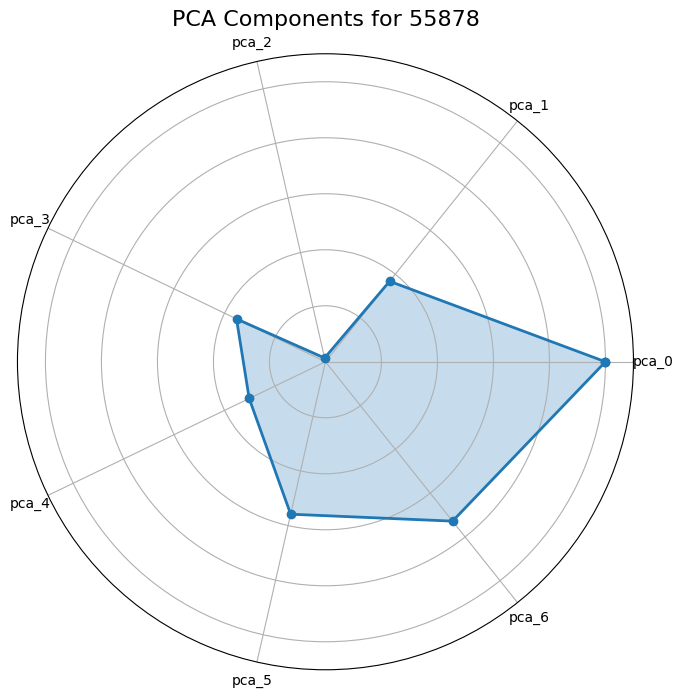

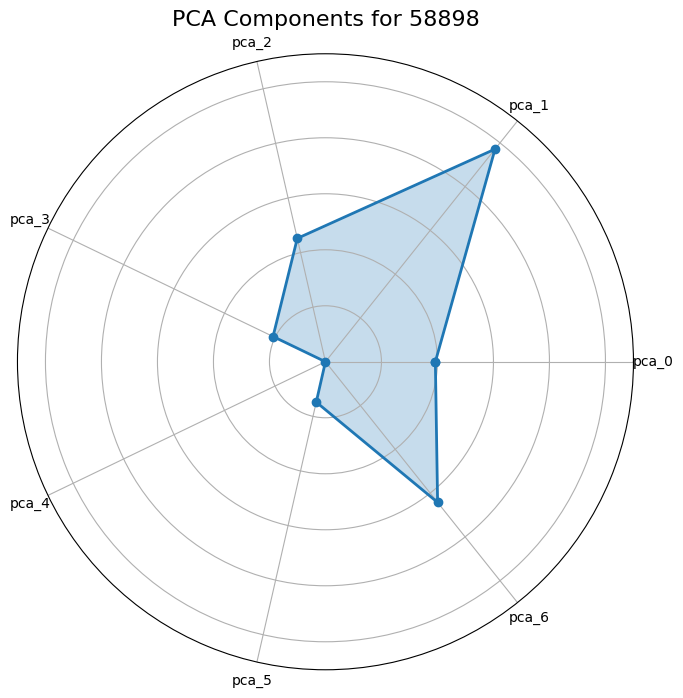

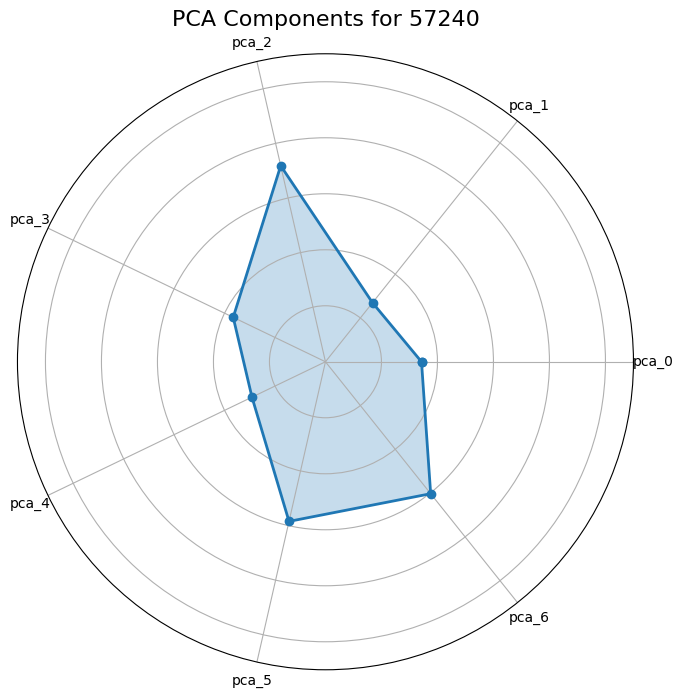

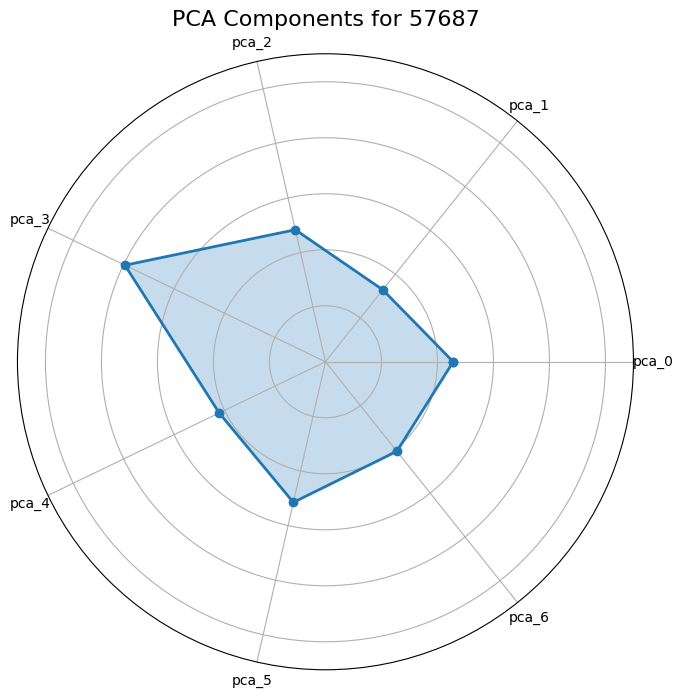

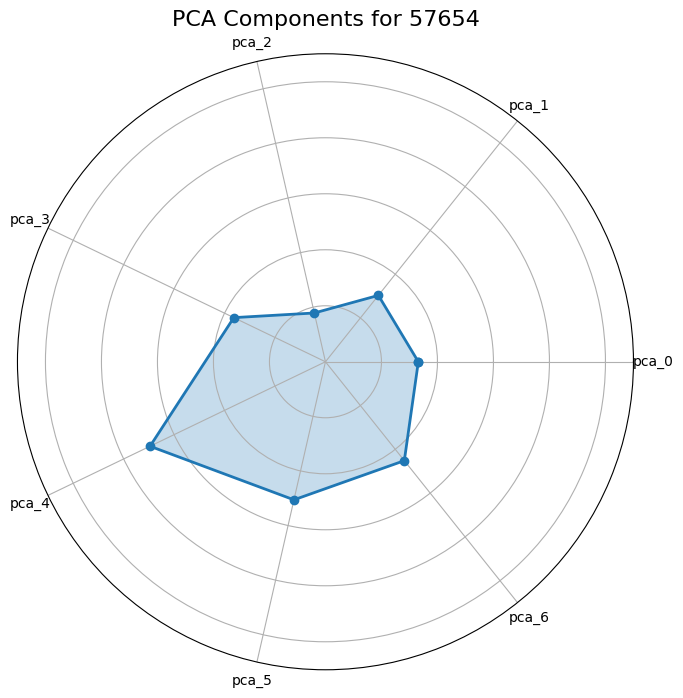

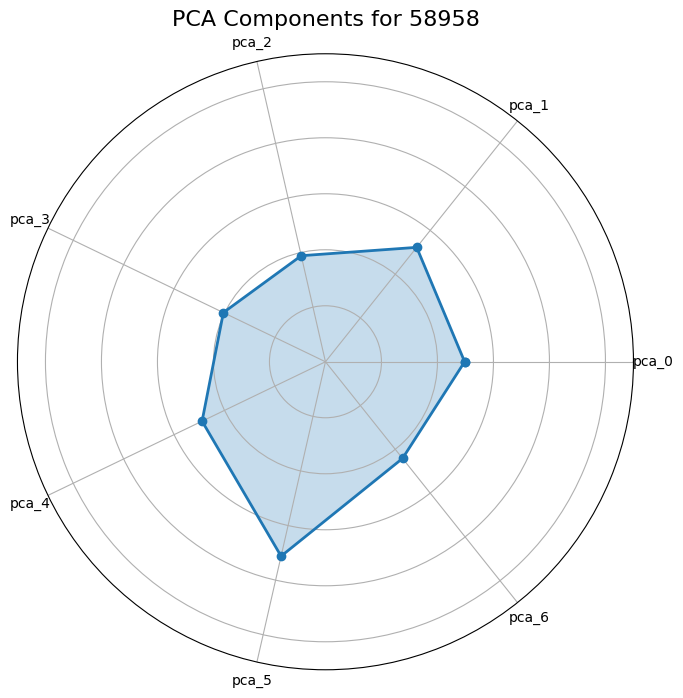

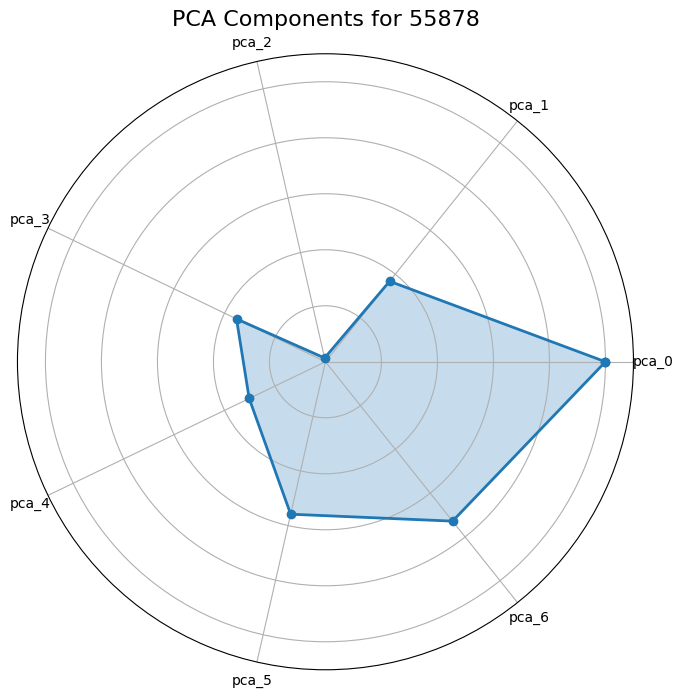

In [37]:
# Example usage:
component_names = ['pca_0', 'pca_1', 'pca_2', 'pca_3', 'pca_4', 'pca_5', 'pca_6']
create_spider_plot(pca_ol, 55878, component_names)
create_spider_plot(pca_ol, 58898, component_names)
create_spider_plot(pca_ol, 57240, component_names)
create_spider_plot(pca_ol, 57687, component_names)
create_spider_plot(pca_ol, 57654, component_names)
create_spider_plot(pca_ol, 58958, component_names)
create_spider_plot(pca_ol, 55878, component_names)

* pca_0 *Dynamic Redirection Capacity*: high (change direction aggressively, generate acceleration repeatedly, spend time turning, sustain turns), low (move efficiently, maintain speed, cover distance cleanly). Rederective Athlete vs Linear Athlete
* pca_1 *Movement Volatility*: High (Variable movement profile Large speed fluctuations) vs low (Consistently forceful movement) - Med confidence here
* pca_2 *Sustained Motor Output* or work rate: (Moves fast, Accelerates frequently, Maintains movement) vs (More economical, More efficient)
* pca_3 *Athletic Floor* or consistency: Even my worst drill is still athletic. Lows are large variability, movement efficiency variability, angular acceleration variability. Possibly the most interesting for OL
* pca_4: *Directional Style*: Turning Style vs Straight-Line Speed, high (turn duration, omega variation, hard turn activity, so turn oriented mover) low (max speed, speed_p90, speed_std or a Speed-oriented mover)
* pca_5 : *Rotational Explosiveness*: accel_std, omega_max, angular acceleration, peak sustained turn vs acceleration consistency, turn-duration consistency
* pca_6: *Movement Density* high (Many movement events, Lots of adjustments, Lots of accelerations) low (Cleaner longer movements)

# DL

In [39]:
tmp = result_pos["DL"].copy()

stats_dl = aggregate_drills(tmp)

pca_dl, loadings_dl = get_pca_components(stats_dl)

Inital shape: (118, 365)
Shape after correlation removed: (118, 233)

Number of drills: 6
Drills: ['BODY_CONTROL_DRILL', 'FOUR_BAG_AGILITY_DRILL', 'FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION', 'PASS_RUSH_DRILL', 'RUN_AND_CLUB_DRILL', 'RUN_THE_HOOP_DRILL']

Number of stats: 48
Stats: ['accel_cv', 'accel_entropy', 'accel_impulse', 'accel_p90', 'accel_p95', 'accel_std', 'angular_accel_std', 'braking_impulse', 'displacement', 'hard_turn_activity', 'jerk_std', 'left_turn_fraction', 'left_turn_max', 'left_turn_mean', 'max_abs_angular_accel', 'max_abs_jerk', 'max_curvature', 'max_speed', 'max_turn_duration', 'mean_abs_angular_accel', 'mean_accel', 'mean_curvature', 'mean_negative_accel', 'mean_speed', 'mean_turn_duration', 'median_speed', 'movement_eccess', 'movement_efficiency', 'n_turns', 'omega_abs_mean', 'omega_max', 'omega_mean', 'peak_braking', 'peak_speed_time', 'peak_sustained_turn', 'right_turn_mean', 'smoothness', 'speed_cv', 'speed_entropy', 'speed_p90', 'speed_p95', 'speed_std', 

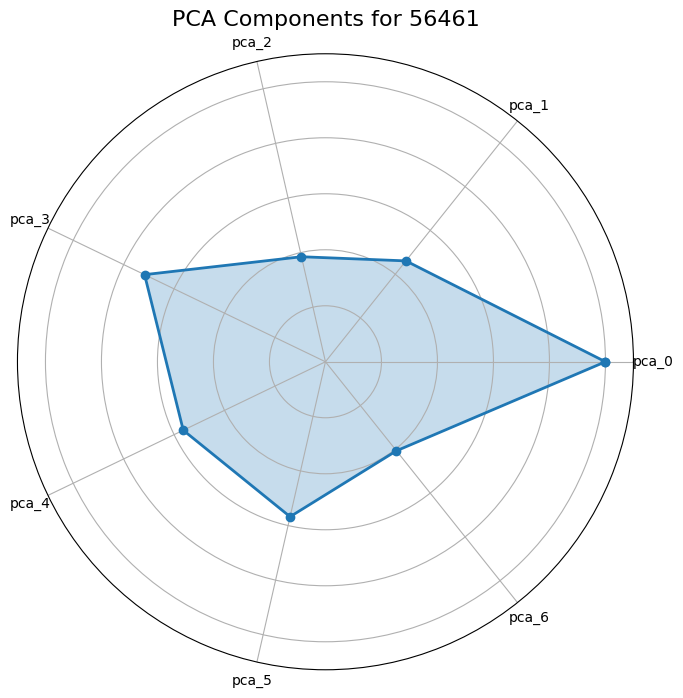

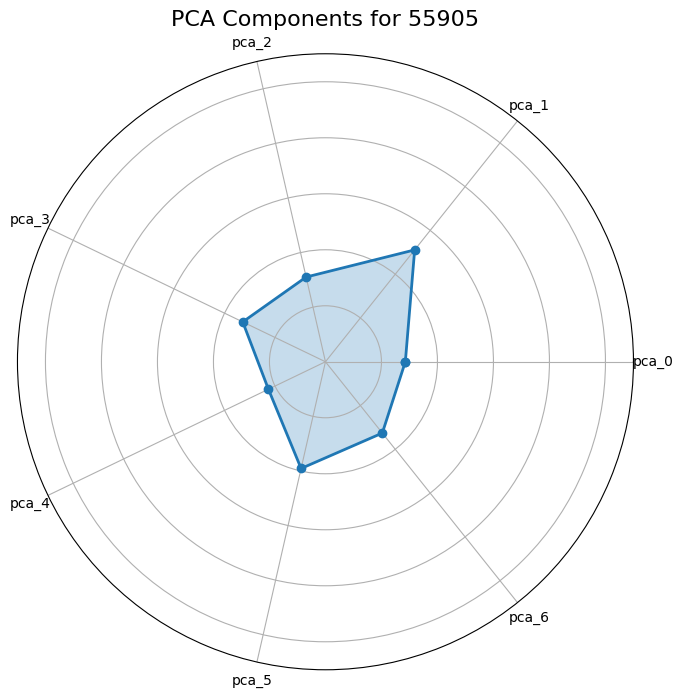

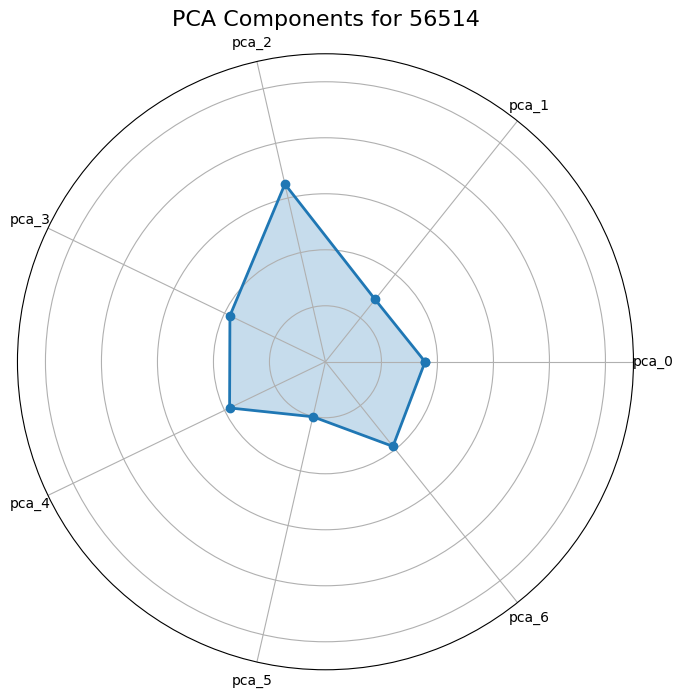

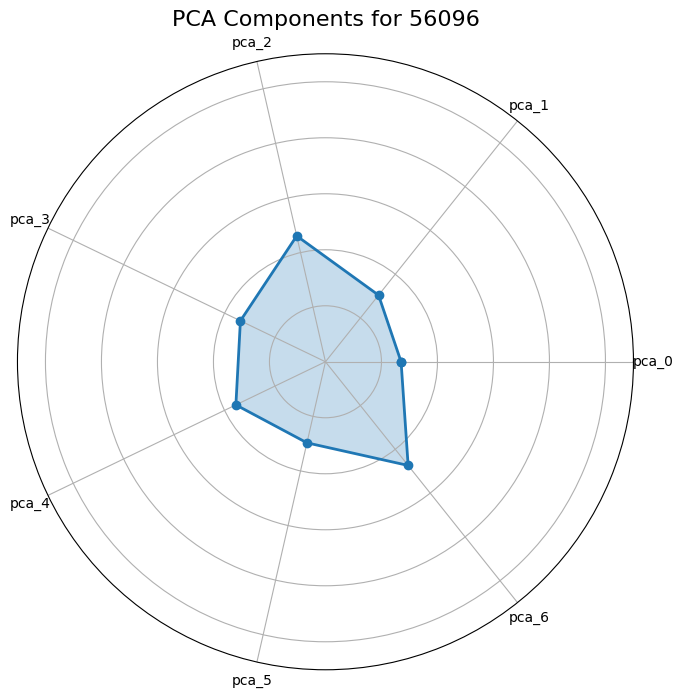

In [48]:
component_names = ['pca_0', 'pca_1', 'pca_2', 'pca_3', 'pca_4', 'pca_5', 'pca_6']
create_spider_plot(pca_dl, 56461, component_names)
create_spider_plot(pca_dl, 55905, component_names)
create_spider_plot(pca_dl, 56514, component_names)
create_spider_plot(pca_dl, 56096, component_names)

* pca_0 *Controlled Mobility*: efficient movers vs violent movers (Smooth, Controlled, Efficient, Always at least moderately athletic) vs (Violent, Aggressive, High-turn-rate mover)
* pca_1 *Motor Output*: high (Produces a lot of movement, Produces a lot of acceleration, Covers a lot of ground), Exactly what we'd expect from a highly active pass-rusher
* pca_2 *Movement Efficiency*: high (Efficient athlete, Direct athlete, Economical mover) low (Explosive but wasteful mover).very clean pca and possibly most valuable
* pca_3 *Rotational Dynamism*: Very pass-rush relevant. dominated by Angular motion, Directional change, Turning aggression
* pca_4 *Acceleration Development*: How quickly speed develops. speed up profile. High Builds speed gradually, low Reaches speed instantly
* pca_5: *Turning Commitment*: Bending around the tackle vs Plant and redirect, Long sustained turns vs Short violent changes
* pca_6: *Bend Ability*: Can the athlete maintain extreme directional change?

# DB

In [49]:
tmp = result_pos["DB"].copy()

stats_db = aggregate_drills(tmp)

pca_db, loadings_db = get_pca_components(stats_db)

Inital shape: (122, 485)
Shape after correlation removed: (122, 288)

Number of drills: 8
Drills: ['BACK_PEDAL_AND_90_DEGREE_BREAK_TO_BALL', 'BACK_PEDAL_AND_TRANSITION_45_DEGREE_REACTION', 'BOX_DRILL', 'FORTY_YARD_DASH', 'GAUNTLET_DRILL', 'TERYL_AUSTIN_DRILL_1', 'TERYL_AUSTIN_DRILL_2', 'W_DRILL']

Number of stats: 45
Stats: ['accel_cv', 'accel_entropy', 'accel_impulse', 'accel_p90', 'accel_p95', 'accel_p99', 'accel_std', 'angular_accel_std', 'braking_impulse', 'displacement', 'hard_turn_activity', 'jerk_std', 'left_turn_fraction', 'left_turn_max', 'left_turn_mean', 'max_abs_jerk', 'max_curvature', 'max_speed', 'max_turn_duration', 'mean_abs_jerk', 'mean_accel', 'mean_curvature', 'mean_negative_accel', 'mean_speed', 'mean_turn_duration', 'median_speed', 'movement_eccess', 'n_turns', 'omega_abs_mean', 'omega_max', 'omega_mean', 'peak_braking', 'peak_speed_time', 'right_turn_mean', 'smoothness', 'speed_cv', 'speed_entropy', 'speed_p90', 'speed_std', 't50_speed', 't75_speed', 't90_speed', 

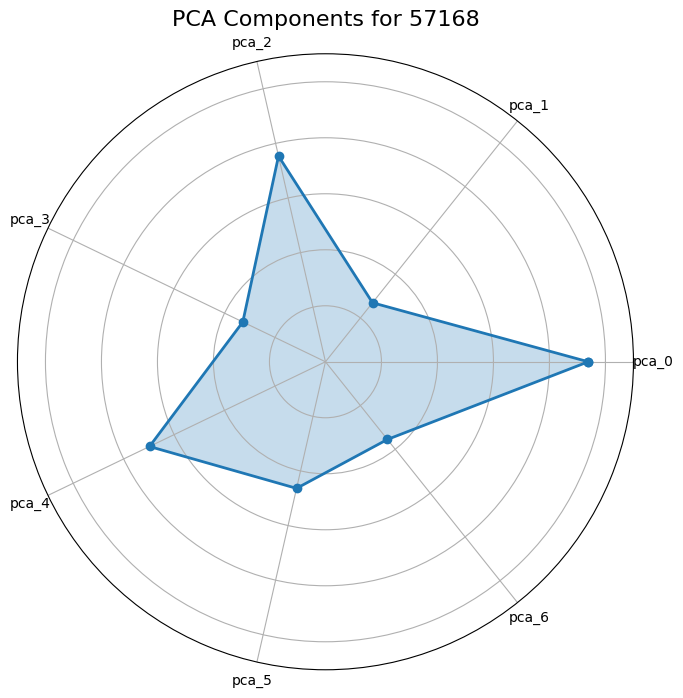

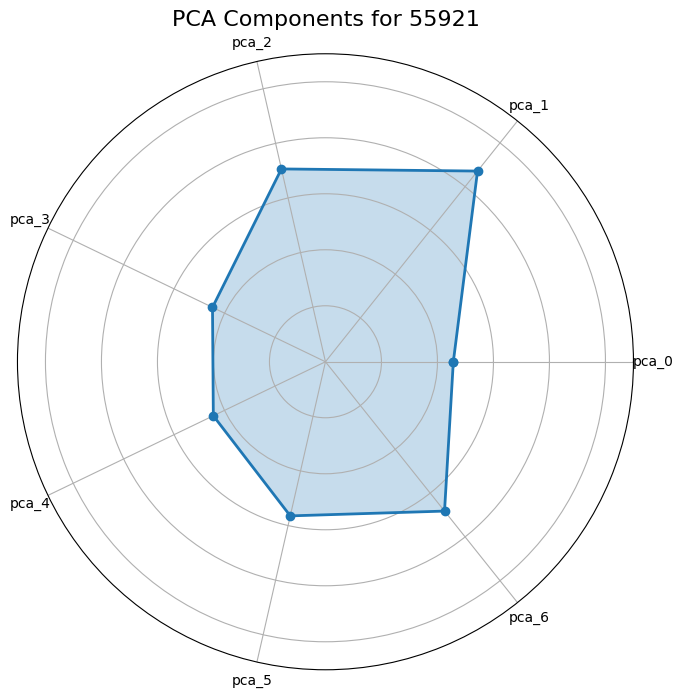

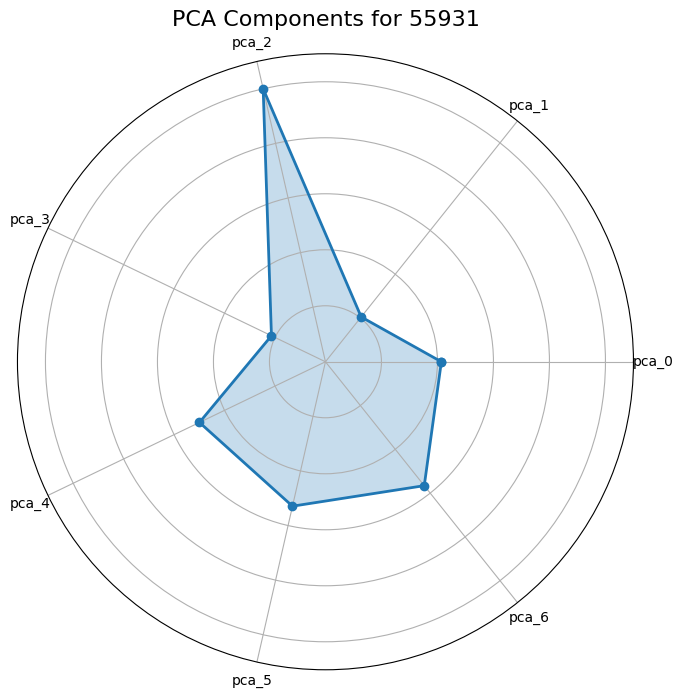

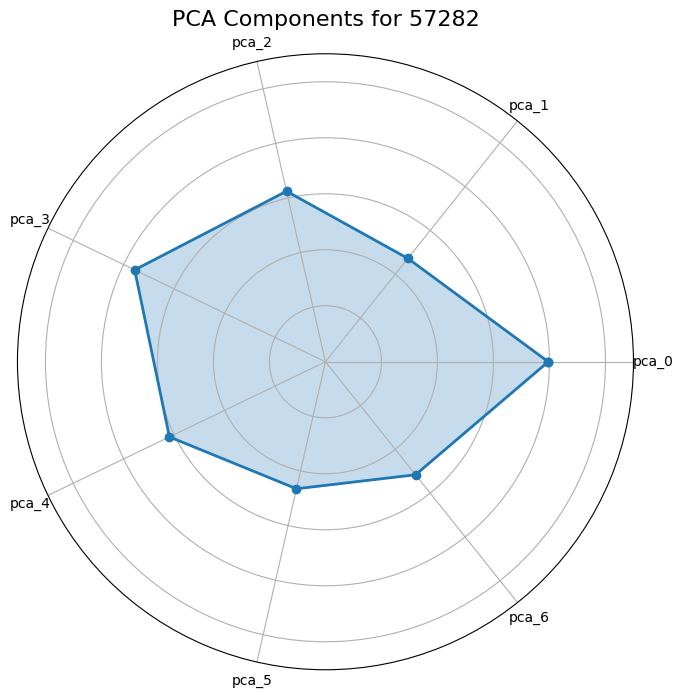

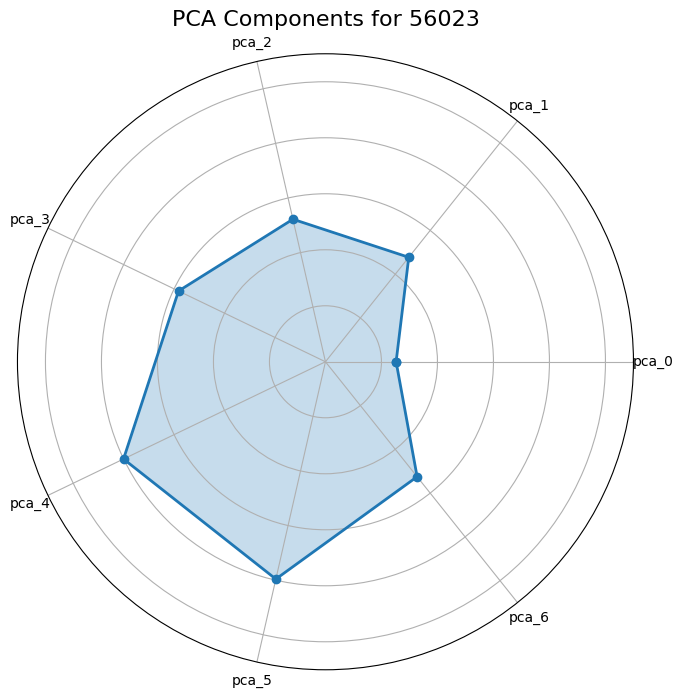

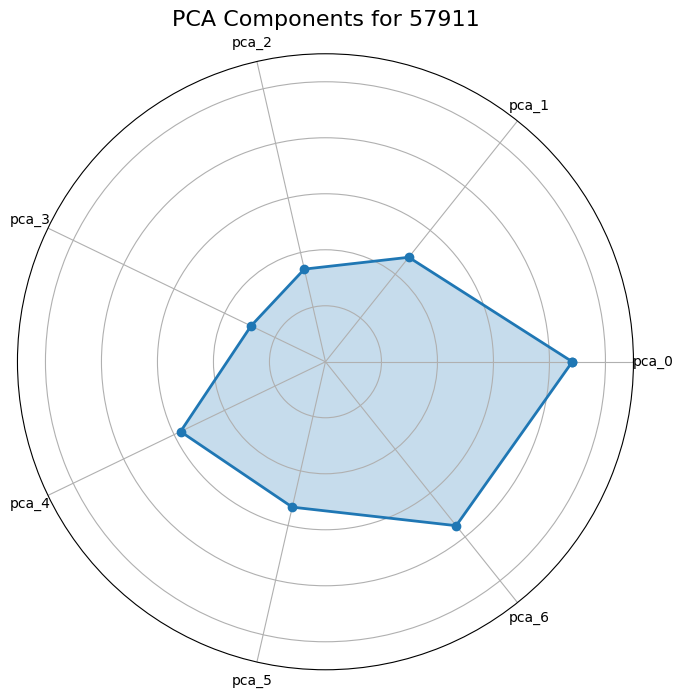

In [57]:
component_names = ['pca_0', 'pca_1', 'pca_2', 'pca_3', 'pca_4', 'pca_5', 'pca_6']
create_spider_plot(pca_db, 57168, component_names)
create_spider_plot(pca_db, 55921, component_names)
create_spider_plot(pca_db, 55931, component_names)
create_spider_plot(pca_db, 57282, component_names)
create_spider_plot(pca_db, 56023, component_names)
create_spider_plot(pca_db, 57911, component_names)

transition
flip hips
change direction
accelerate
recover

* pca_0 *Reactive Movement Density*: How "busy" is the athlete's movement profile?, High (Lots of cuts, Lots of adjustments, Lots of directional changes) vs low (Linear movement, Covering ground, Generating speed)
* pca_1 *Athletic Floor*, similar to OL. Even the player's worst drill remains athletic and movement-rich
* pca_2 *Explosive Coverage Range*: Less about turning, more about range. Covers ground, Accelerates violently, Has recovery speed
* pca_3 *Speed Ceiling* or recovery speed; How much top-end speed can you access? very clear component
* pca_4 *Transition Control* or braking ability; Able to decelerate, Flip, Plant, Transition
* pca_5: *Explosive Directional Change*, db version of OL *Rotational Explosiveness*: How rapidly can the athlete redirect momentum?
* pca_6: *Turning Asymmetry* This may reflect: foot dominance drill structure measurement artifact Rather than a fundamental athletic trait. Low confidence

# TE

In [58]:
tmp = result_pos["TE"].copy()

stats_te = aggregate_drills(tmp)

pca_te, loadings_te = get_pca_components(stats_te)

Inital shape: (42, 431)
Shape after correlation removed: (42, 241)

Number of drills: 7
Drills: ['BLOCK_EXPLOSION', 'FLAT_ROUTE_LEFT', 'FORTY_YARD_DASH', 'GAUNTLET_DRILL', 'HOOK_ROUTE_RIGHT', 'IN_ROUTE_LEFT', 'WHEEL_ROUTE_LEFT']

Number of stats: 44
Stats: ['accel_cv', 'accel_entropy', 'accel_impulse', 'accel_p90', 'accel_p95', 'accel_std', 'angular_accel_std', 'braking_impulse', 'displacement', 'hard_turn_activity', 'jerk_std', 'left_turn_fraction', 'left_turn_max', 'left_turn_mean', 'max_abs_jerk', 'max_curvature', 'max_speed', 'max_turn_duration', 'mean_abs_jerk', 'mean_accel', 'mean_negative_accel', 'mean_speed', 'mean_turn_duration', 'median_speed', 'movement_eccess', 'movement_efficiency', 'n_turns', 'omega_abs_mean', 'omega_max', 'omega_mean', 'peak_braking', 'peak_speed_time', 'right_turn_mean', 'smoothness', 'speed_cv', 'speed_entropy', 'speed_p90', 'speed_std', 't50_speed', 't75_speed', 't90_speed', 'total_distance', 'turn_activity', 'turn_bias']
Final shape: (42, 177)
PCA re

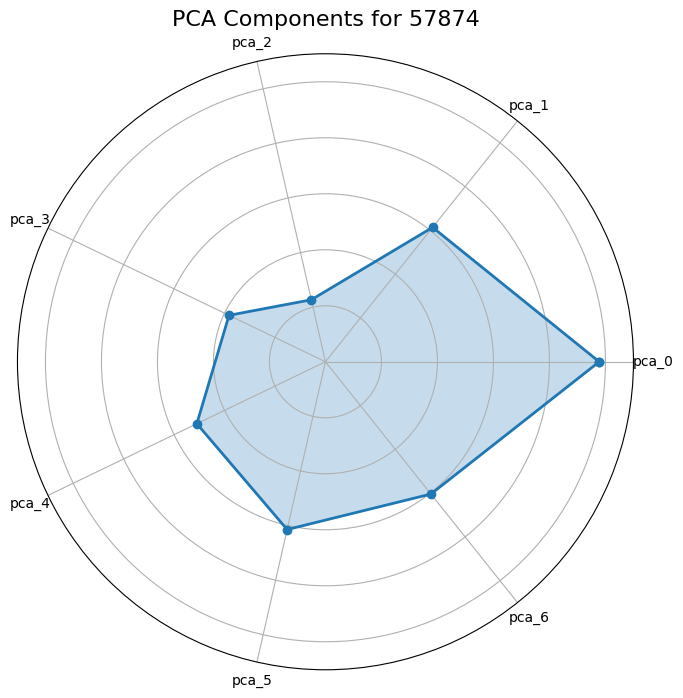

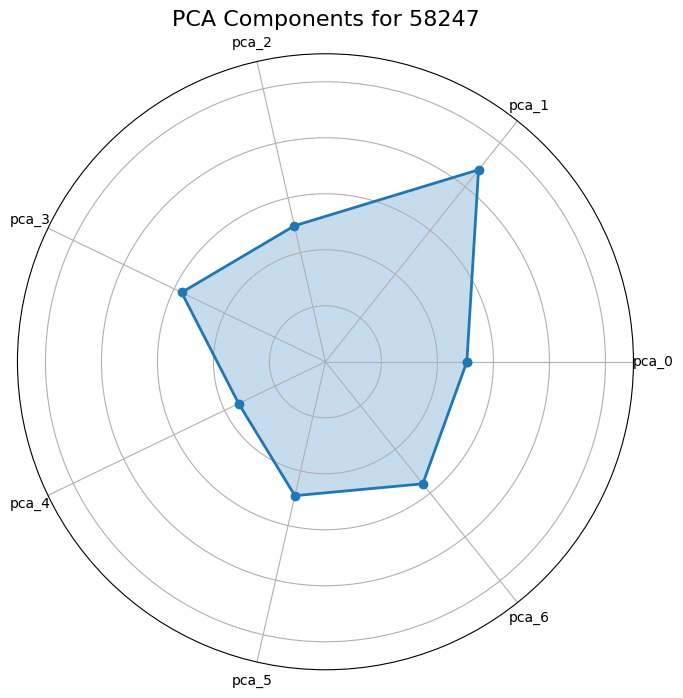

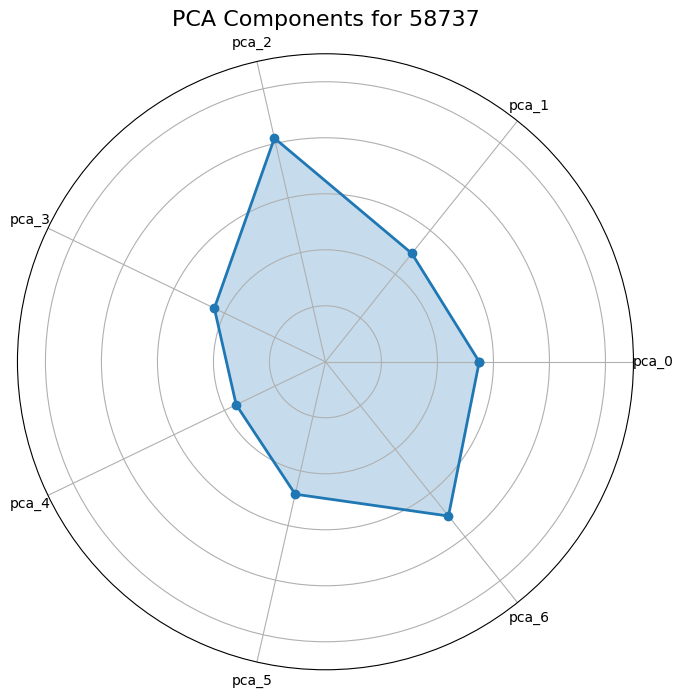

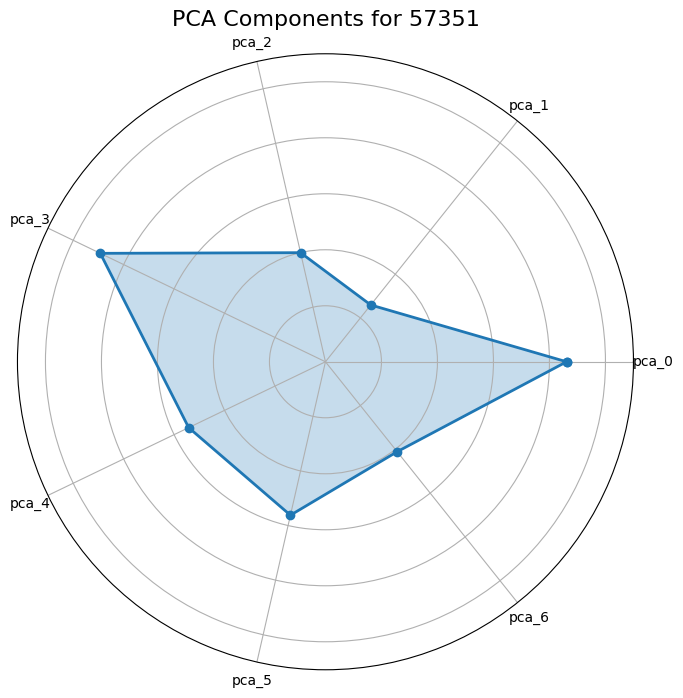

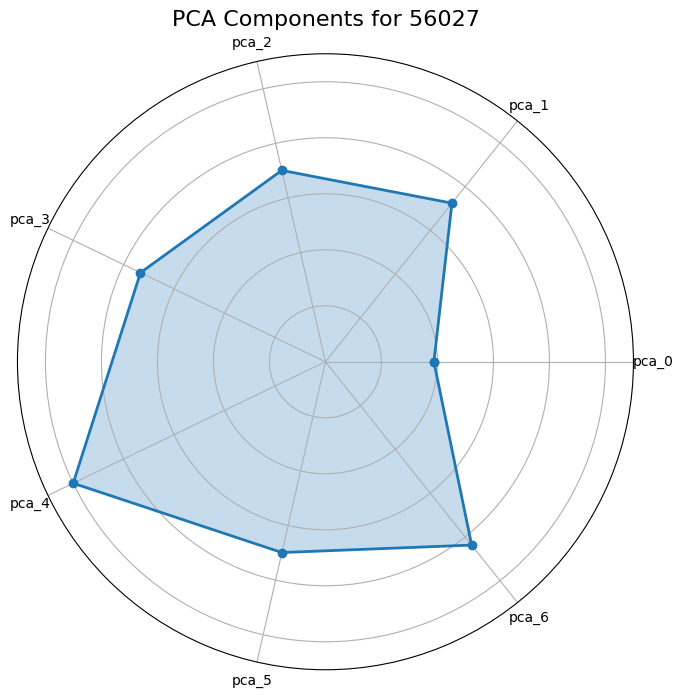

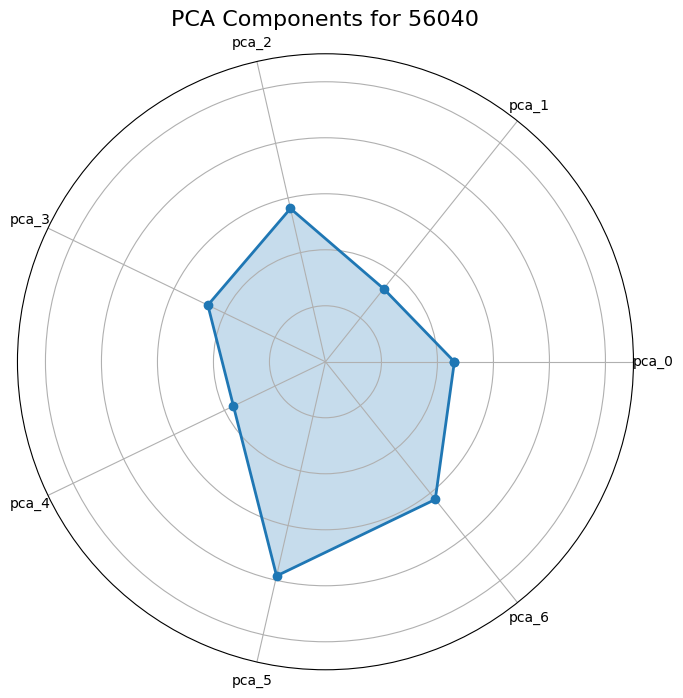

In [59]:
component_names = ['pca_0', 'pca_1', 'pca_2', 'pca_3', 'pca_4', 'pca_5', 'pca_6']
used = []
for comp in component_names:
    nfl_id = pca_te[pca_te[comp] == pca_te[comp].max()]["nfl_id"].values[0]
    if nfl_id in used:
        continue
    used.append(nfl_id)
    create_spider_plot(pca_te, nfl_id, component_names)

receiver traits
+
blocking traits
+
general athleticism

* pca_0 *Route Agility*: This is very similar to the OL Dynamic Redirection component. Lots of cuts, Lots of changes in direction, Route-style movement vs Straight-line mover
* pca_1 *Athletic Floor*: Even worst observed movement performance remains athletic.
* pca_2 *Explosive Space Creation*: Ability to generate movement range and create separation space. It's speed plus acceleration plus movement range.
* pca_3: *Violent Athleticism* or Explosive Athleticism: Fast speed development Large force changes Explosive movement
* pca_4: *Speed Development Profile* This is very similar to the DL acceleration-development PC. Gradual speed builder vs Immediately explosive athlete
* pca_5: *Movement Complexity* Complex, varied movement patterns. entropy turn asymmetry movement variability. Medium confidence
* pca_6: *Controlled Physicality* or power control. Blocking movement quality mixed with athleticism.


# WR

In [60]:
tmp = result_pos["WR"].copy()

stats_wr = aggregate_drills(tmp)

pca_wr, loadings_wr = get_pca_components(stats_wr)

Inital shape: (107, 725)
Shape after correlation removed: (107, 436)

Number of drills: 12
Drills: ['COMEBACK_ROUTE_RIGHT', 'CURL_ROUTE_RIGHT', 'DAGGER_ROUTE_LEFT', 'FORTY_YARD_DASH', 'GAUNTLET_DRILL', 'GO_ROUTE_RIGHT', 'OVER_SHOULDER_ADJUST', 'POST_CORNER_ROUTE_RIGHT', 'RED_ZONE_FADE_RIGHT', 'SLANT_ROUTE_LEFT', 'SLOT_SAIL_ROUTE_RIGHT', 'SLOT_STRIKE_ROUTE_LEFT']

Number of stats: 46
Stats: ['accel_cv', 'accel_entropy', 'accel_impulse', 'accel_p90', 'accel_p95', 'accel_std', 'angular_accel_std', 'braking_impulse', 'displacement', 'hard_turn_activity', 'jerk_std', 'left_turn_fraction', 'left_turn_max', 'left_turn_mean', 'max_abs_jerk', 'max_curvature', 'max_speed', 'max_turn_duration', 'mean_abs_jerk', 'mean_accel', 'mean_curvature', 'mean_negative_accel', 'mean_speed', 'mean_turn_duration', 'median_speed', 'movement_eccess', 'movement_efficiency', 'n_turns', 'omega_abs_max', 'omega_abs_mean', 'omega_max', 'omega_mean', 'peak_braking', 'peak_speed_time', 'right_turn_mean', 'smoothness', 

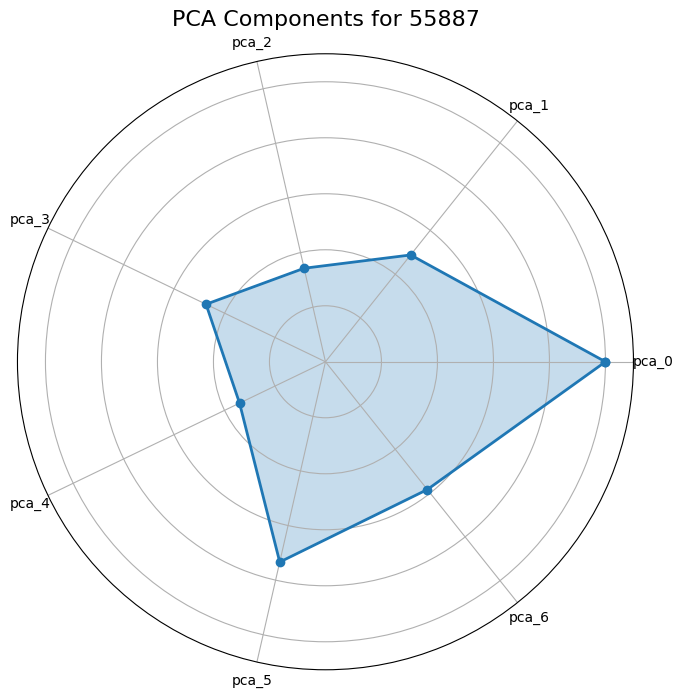

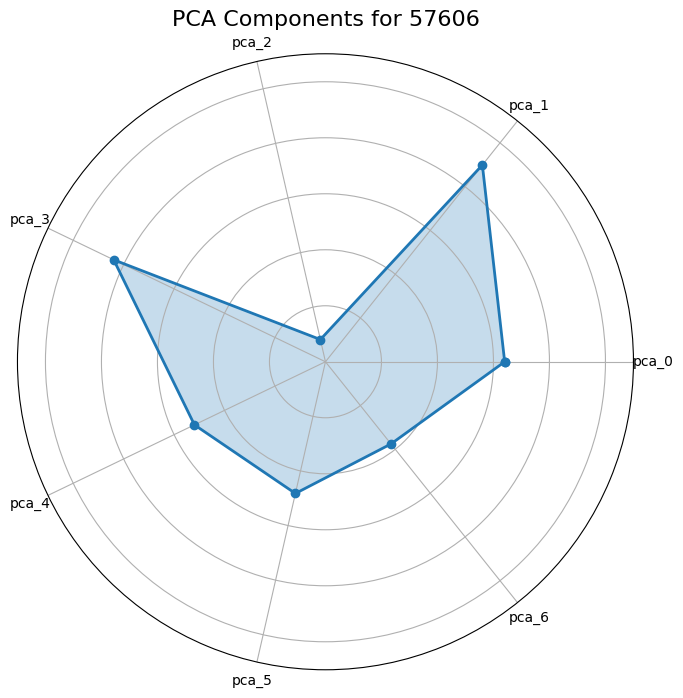

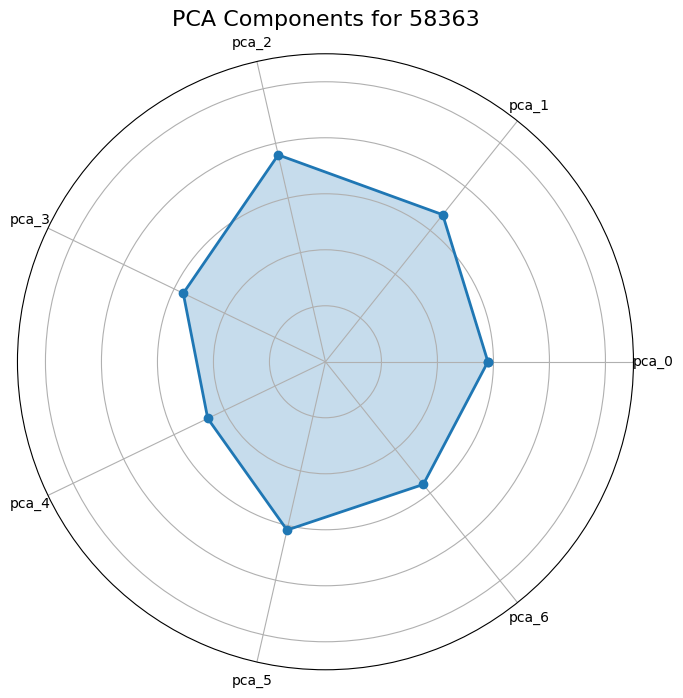

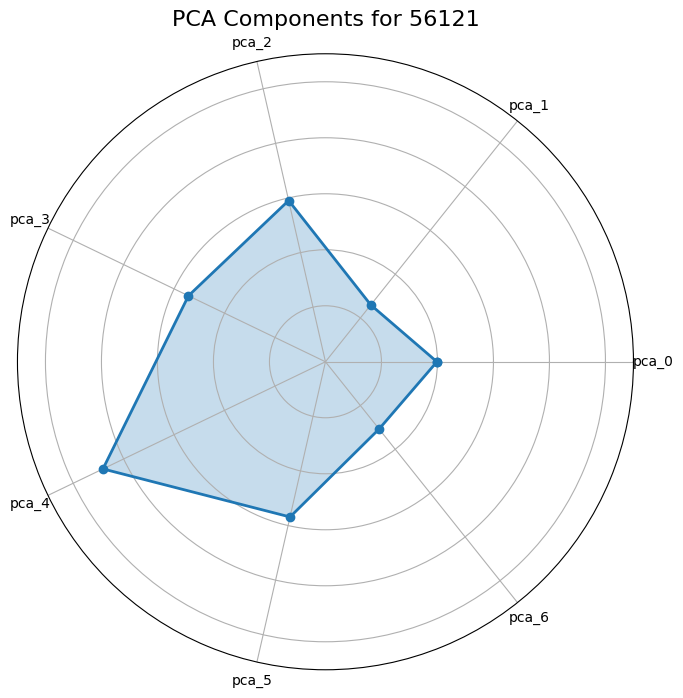

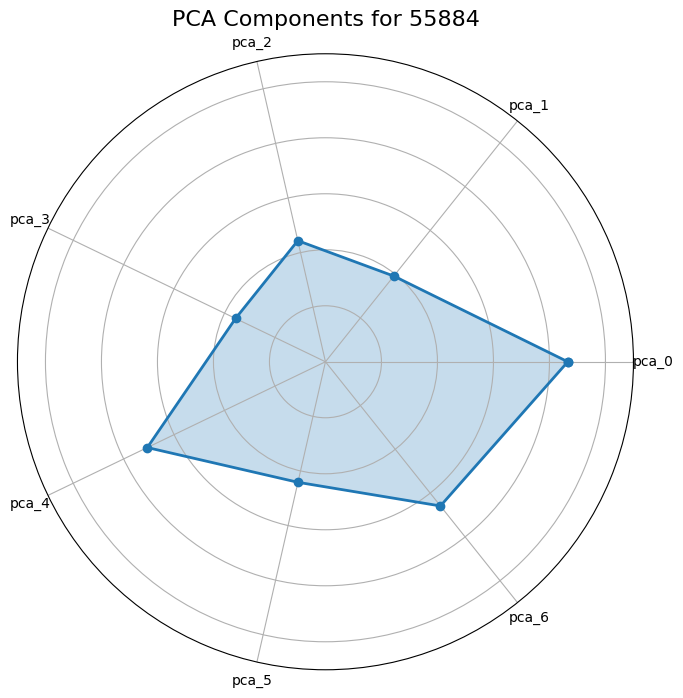

In [61]:
component_names = ['pca_0', 'pca_1', 'pca_2', 'pca_3', 'pca_4', 'pca_5', 'pca_6']
used = []
for comp in component_names:
    nfl_id = pca_wr[pca_wr[comp] == pca_wr[comp].max()]["nfl_id"].values[0]
    if nfl_id in used:
        continue
    used.append(nfl_id)
    create_spider_plot(pca_wr, nfl_id, component_names)

WR dimensions are remarkably intuitive and align strongly with concepts route-running coaches already use.

* pca_0 *Route Athletic Floor*: How athletic are you on your worst route? Consistently athletic across all routes. vs Big drop-off between best and worst routes. 
* pca_1 *Route Density*: This is very similar to DB PCA0. or route complexity. Slot technician vs Vertical receiver. Constantly cutting Constantly changing pace Constantly redirecting vs Linear route runner
* pca_2 *Route Burst* How explosively can you generate movement? Burst out of breaks Burst into routes Create separation explosively
* pca_3 *Violent Separation Ability* or Break Explosiveness: Explosive Abrupt Violent movement very good component
* pca_4 *Athletic Variability*: How much does performance fluctuate from route to route? Huge ceiling Huge variation vs Same athlete every route
* pca_5 *Playmaking Range* or Field-Stretching Ability: How much field can you cover? mor than how explosive, Vertical threat more than quick separator
* pca_6 *Directional Bias* Just like DB PCA6. This may represent: route inventory bias foot dominance handedness measurement artifacts or a real athletic asymmetry. Medium, to verify


Across all positions, I now see recurring latent dimensions.

Dimension Family 1

Found everywhere:

Plain Text
Athletic Floor

Examples:

Plain Text
WR PCA0
DB PCA1
TE PCA1
OL PCA3

This may be a universal athletic trait.

Dimension Family 2

Found everywhere:

Plain Text
Burst / Explosiveness

Examples:

Plain Text
WR PCA2
WR PCA3
DL PCA1
OL PCA5
Dimension Family 3

Found everywhere:

Plain Text
Direction Change Ability

Examples:

Plain Text
DB Transition Control
DL Rotational Dynamism
WR Route Density
OL Dynamic Redirection
Dimension Family 4

Found everywhere:

Plain Text
Movement Efficiency

Very visible in DL and somewhat present elsewhere.

Position-specific PCs
       ↓
Manually grouped into
global movement dimensions

Athletic Floor
Burst
Directional Change
Efficiency
Complexity
Directional Bias